# Main-concept cutoff sensitivity analysis

This notebook reproduces the preliminary **utterance-level** sensitivity analysis for the main-concept cutoff $\mu + k\sigma$. It compares thresholded centroid distances with human main-concept labels for 1,466 utterances.

It does **not** regenerate participant features or retrain the downstream diagnostic logistic-regression classifier.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

# This works when the notebook is launched from either the repository root
# or the notebooks directory.
cwd = Path.cwd().resolve()
repo_root = cwd if (cwd / 'data').exists() else cwd.parent

ground_truth_path = repo_root / 'data' / 'Matching_Concept_All_Combined.csv'
automated_path = repo_root / 'data' / 'matching_mainconcept_all_predicted_output.csv'
stats_path = repo_root / 'src' / 'batch_stats_all.csv'

ground_truth_path, automated_path, stats_path

(PosixPath('/projectnb/skiran/Cassie/automated-main-concept-analysis/data/Matching_Concept_All_Combined.csv'),
 PosixPath('/projectnb/skiran/Cassie/automated-main-concept-analysis/data/matching_mainconcept_all_predicted_output.csv'),
 PosixPath('/projectnb/skiran/Cassie/automated-main-concept-analysis/src/batch_stats_all.csv'))

In [2]:
ground_truth = pd.read_csv(ground_truth_path)
automated = pd.read_csv(automated_path)
stats = pd.read_csv(stats_path)

assert len(ground_truth) == len(automated), (len(ground_truth), len(automated))

# The prediction file does not contain participant IDs, so verify that its
# utterances are in exactly the same order as the human-coded file.
human_text = ground_truth['utterances'].fillna('').str.strip()
automated_text = automated['utterance'].fillna('').str.strip()
alignment = human_text.eq(automated_text)
assert alignment.all(), f'{(~alignment).sum()} utterances are not aligned'

print(f'Rows: {len(ground_truth):,}')
print(f'Utterance alignment: {alignment.mean():.1%}')

Rows: 1,466
Utterance alignment: 100.0%


In [3]:
# Parse the human main-concept judgment explicitly and fail if any value
# is not recognizable as True or False.
y_true = (
    ground_truth['Ground Truth Matching?']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'true': True, 'false': False})
)
assert y_true.notna().all(), 'Unrecognized human ground-truth value found'
y_true = y_true.astype(bool).to_numpy()

distances = pd.to_numeric(
    automated['distance_to_centroid'], errors='raise'
).to_numpy()

# Use the final pooled values recorded by the original batch calculation.
mean_distance = float(stats.iloc[-1]['cum_mean_dist'])
sd_distance = float(stats.iloc[-1]['cum_std_dist'])
original_cutoff = float(stats.iloc[-1]['cum_cutoff'])

print(f'Mean distance: {mean_distance:.10f}')
print(f'SD distance:   {sd_distance:.10f}')
print(f'Original cutoff (k=1): {original_cutoff:.10f}')
print(f'Human-positive prevalence: {y_true.mean():.3f}')

Mean distance: 0.6463490725
SD distance:   0.1828766018
Original cutoff (k=1): 0.8292256743
Human-positive prevalence: 0.731


In [4]:
def evaluate_cutoff_sensitivity(y_true, distances, mean_distance, sd_distance, k_values):
    rows = []

    for k in k_values:
        cutoff = mean_distance + k * sd_distance
        y_pred = distances <= cutoff

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average='binary', zero_division=0
        )
        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[False, True]
        ).ravel()

        rows.append({
            'k': k,
            'cutoff': cutoff,
            'accuracy': accuracy_score(y_true, y_pred),
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'specificity': tn / (tn + fp),
            'tn': tn,
            'fp': fp,
            'fn': fn,
            'tp': tp,
        })

    return pd.DataFrame(rows)

# These alternative k values are analyst-selected scenarios that bracket
# the original k=1 choice; they were not read from the project files.
k_values = [0.50, 0.75, 1.00, 1.25, 1.50]
results = evaluate_cutoff_sensitivity(
    y_true, distances, mean_distance, sd_distance, k_values
)

results.round({
    'cutoff': 4,
    'accuracy': 3,
    'balanced_accuracy': 3,
    'precision': 3,
    'recall': 3,
    'f1': 3,
    'specificity': 3,
})

,k,cutoff,accuracy,balanced_accuracy,precision,recall,f1,specificity,tn,fp,fn,tp
0,0.50,0.7378,0.802,0.783,0.897,0.823,0.858,0.744,294,101,190,881
1,0.75,0.7835,0.829,0.771,0.872,0.898,0.885,0.643,254,141,109,962
2,1.00,0.8292,0.826,0.719,0.834,0.951,0.889,0.486,192,203,52,1019
3,1.25,0.8749,0.777,0.598,0.772,0.986,0.866,0.210,83,312,15,1056
4,1.50,0.9207,0.753,0.545,0.749,0.996,0.855,0.094,37,358,4,1067


## Visualization of the threshold trade-off

The left panel highlights that $k=1.00$ produced the highest **positive-class F1**. The right panel shows why this should not be described as the best value for every metric: increasing $k$ improves recall but reduces precision and specificity.

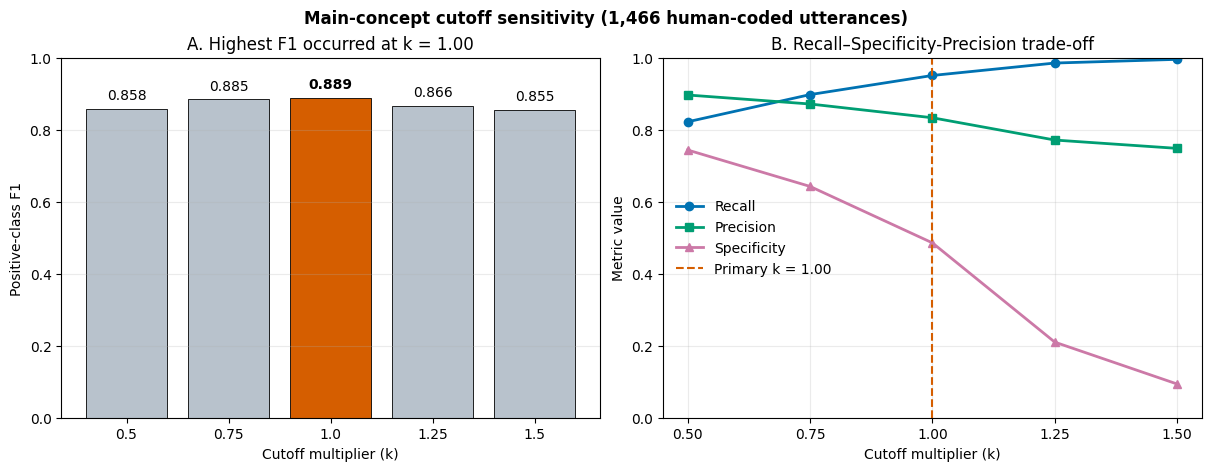

In [12]:
import matplotlib.pyplot as plt

primary_k = 1.00
is_primary = np.isclose(results['k'], primary_k)
colors = np.where(is_primary, '#D55E00', '#B8C2CC')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)

axes[0].bar(results['k'].astype(str), results['f1'], color=colors, edgecolor='black', linewidth=0.6)
axes[0].set_ylim(0, 1.0)
axes[0].set_xlabel('Cutoff multiplier (k)')
axes[0].set_ylabel('Positive-class F1')
axes[0].set_title('A. Highest F1 occurred at k = 1.00')
axes[0].grid(axis='y', alpha=0.25)

for i, row in results.reset_index(drop=True).iterrows():
    label = f"{row['f1']:.3f}"
    weight = 'bold' if np.isclose(row['k'], primary_k) else 'normal'
    axes[0].text(i, row['f1'] + 0.018, label, ha='center', va='bottom', fontweight=weight)

metric_styles = {
    'recall': ('Recall', '#0072B2', 'o'),
    'precision': ('Precision', '#009E73', 's'),
    'specificity': ('Specificity', '#CC79A7', '^'),
}
for column, (label, color, marker) in metric_styles.items():
    axes[1].plot(results['k'], results[column], label=label, color=color, marker=marker, linewidth=2)

axes[1].axvline(primary_k, color='#D55E00', linestyle='--', linewidth=1.5, label='Primary k = 1.00')
axes[1].set_ylim(0, 1.0)
axes[1].set_xticks(results['k'])
axes[1].set_xlabel('Cutoff multiplier (k)')
axes[1].set_ylabel('Metric value')
axes[1].set_title('B. Recall–Specificity-Precision trade-off')
axes[1].grid(alpha=0.25)
axes[1].legend(frameon=False, loc='center left')

fig.suptitle('Main-concept cutoff sensitivity (1,466 human-coded utterances)', fontweight='bold')
plt.show()

# Optional: save a publication-quality copy.
figure_path = repo_root / 'data' / 'classification' / 'mainconcept_cutoff_sensitivity.png'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')

In [11]:
# Optional: save the reproducible results alongside the existing
# classification outputs. Uncomment these lines if desired.
output_path = repo_root / 'data' / 'classification' / 'mainconcept_cutoff_sensitivity.csv'
results.to_csv(output_path, index=False)
output_path

PosixPath('/projectnb/skiran/Cassie/automated-main-concept-analysis/data/classification/mainconcept_cutoff_sensitivity.csv')

## Interpretation boundary

The positive class is an utterance that human raters designated as related to a Cinderella main concept. Larger $k$ values make the cutoff more permissive, normally increasing recall and decreasing specificity.

For a full pipeline sensitivity analysis, participant features must be regenerated and the downstream logistic regression retrained separately for every $k$ within the original cross-validation folds.